# House Prices in Ames, Iowa — Cleaning, Feature Engineering and EDA

**Scope.** This notebook is the data-preparation and exploratory half of the project:
it audits the two Kaggle files, repairs and imputes the data, engineers features,
and produces the evidence behind the *Introduction* and *Dataset Description*
sections of the report. Modelling is handled separately by the modelling section.

The project's three research questions frame the analysis: RQ1 (which features drive
price), RQ2 (multicollinearity and VIF), RQ3 (influential outliers and regularisation).
This notebook provides the evidence for RQ1, the correlation structure that RQ2 needs,
and the outlier flag that RQ3's with-and-without comparison depends on.

**Data.** `train.csv` (1,460 sales with `SalePrice`) and `test.csv` (1,459 sales
without it), 79 explanatory variables plus `Id`.

**Output of this notebook**

| File | Content |
|---|---|
| `data/train_clean.csv`, `data/test_clean.csv` | cleaned data, original columns, flags |
| `data/train_features.csv`, `data/test_features.csv` | model-ready numeric matrix |
| `reports/audit.json` | every audit number quoted in the report |
| `figures/*.png`, `tables/*.csv` | report exhibits |


## 1. Setup

The pipeline lives in `code/house_prices_pipeline.py` so that the notebook, the
figures and the report cannot drift apart. Pandas 3 stores text in `StringDtype`,
which matters later when one-hot encoding.


In [1]:
import sys, json, warnings
from pathlib import Path

sys.path.insert(0, "code")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import house_prices_pipeline as hp

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

print("pandas", pd.__version__, "| numpy", np.__version__)
print("working directory:", Path.cwd().name)

pandas 3.0.1 | numpy 1.26.4
working directory: house-prices


## 2. First look at the two files

The target exists only in the training file, and the test file has no
`SalePrice` column at all. Every transformation below is therefore fitted on
`train` and applied unchanged to `test`.


In [2]:
train, test = hp.load_raw()
print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"test : {test.shape[0]:,} rows x {test.shape[1]} columns")
print("target column present in test:", "SalePrice" in test.columns)
display(train.iloc[:4, :8])

train: 1,460 rows x 81 columns
test : 1,459 rows x 80 columns
target column present in test: False


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape
0,1,60,RL,65.0,8450,Pave,NaN,Reg
1,2,20,RL,80.0,9600,Pave,NaN,Reg
2,3,60,RL,68.0,11250,Pave,NaN,IR1
3,4,70,RL,60.0,9550,Pave,NaN,IR1


### 2.1 Audit

Duplicate ids, duplicate rows, constant columns and the shape of the target are
checked before anything is changed. The numbers are written to
`reports/audit.json` and quoted verbatim in the report.


In [3]:
audit = hp.audit(train, test)
for k in ["n_train", "n_test", "n_features", "duplicate_ids", "duplicate_rows",
          "cols_with_missing_train", "cols_with_missing_test",
          "total_missing_cells_train", "pct_missing_cells_train",
          "target_mean", "target_median", "target_std", "target_min", "target_max",
          "target_skew", "target_log_skew"]:
    print(f"{k:>28}: {audit[k]}")

                     n_train: 1460
                      n_test: 1459
                  n_features: 79
               duplicate_ids: 0
              duplicate_rows: 0
     cols_with_missing_train: 19
      cols_with_missing_test: 33
   total_missing_cells_train: 7829
     pct_missing_cells_train: 6.62
                 target_mean: 180921.2
               target_median: 163000.0
                  target_std: 79442.5
                  target_min: 34900
                  target_max: 755000
                 target_skew: 1.883
             target_log_skew: 0.121


### 2.2 Missing values — structural versus true

Nineteen columns are incomplete in the training file, but most of the blanks are
not data errors. The data dictionary defines `NA` for `PoolQC`, `Alley`,
`Fence`, `FireplaceQu`, the basement and the garage blocks as *"the house does
not have this feature"*. Filling those with a statistic would invent basements
and fireplaces. Only `LotFrontage` (17.7%), a handful of `MasVnrArea` cells and a
single `Electrical` value are genuinely missing.


In [4]:
miss = hp.missing_table(train, test)
display(miss.head(12))
print("structural rows:", (miss.interpretation.str.startswith("Structural")).sum(),
      "| true-missing rows:", (~miss.interpretation.str.startswith("Structural")).sum())

,column,missing_train,pct_train,missing_test,interpretation
30,PoolQC,1453,99.52,1456,Structural: NA = no feature (basement/garage/p...
32,MiscFeature,1406,96.30,1408,Structural: NA = no feature (basement/garage/p...
2,Alley,1369,93.77,1352,Structural: NA = no feature (basement/garage/p...
31,Fence,1179,80.75,1169,Structural: NA = no feature (basement/garage/p...
6,MasVnrType,872,59.73,894,Structural: NA = no feature (basement/garage/p...
22,FireplaceQu,690,47.26,730,Structural: NA = no feature (basement/garage/p...
1,LotFrontage,259,17.74,227,True missing: not recorded in the assessor file
23,GarageType,81,5.55,76,Structural: NA = no feature (basement/garage/p...
24,GarageYrBlt,81,5.55,78,Structural: no garage
25,GarageFinish,81,5.55,78,Structural: NA = no feature (basement/garage/p...


structural rows: 21 | true-missing rows: 13


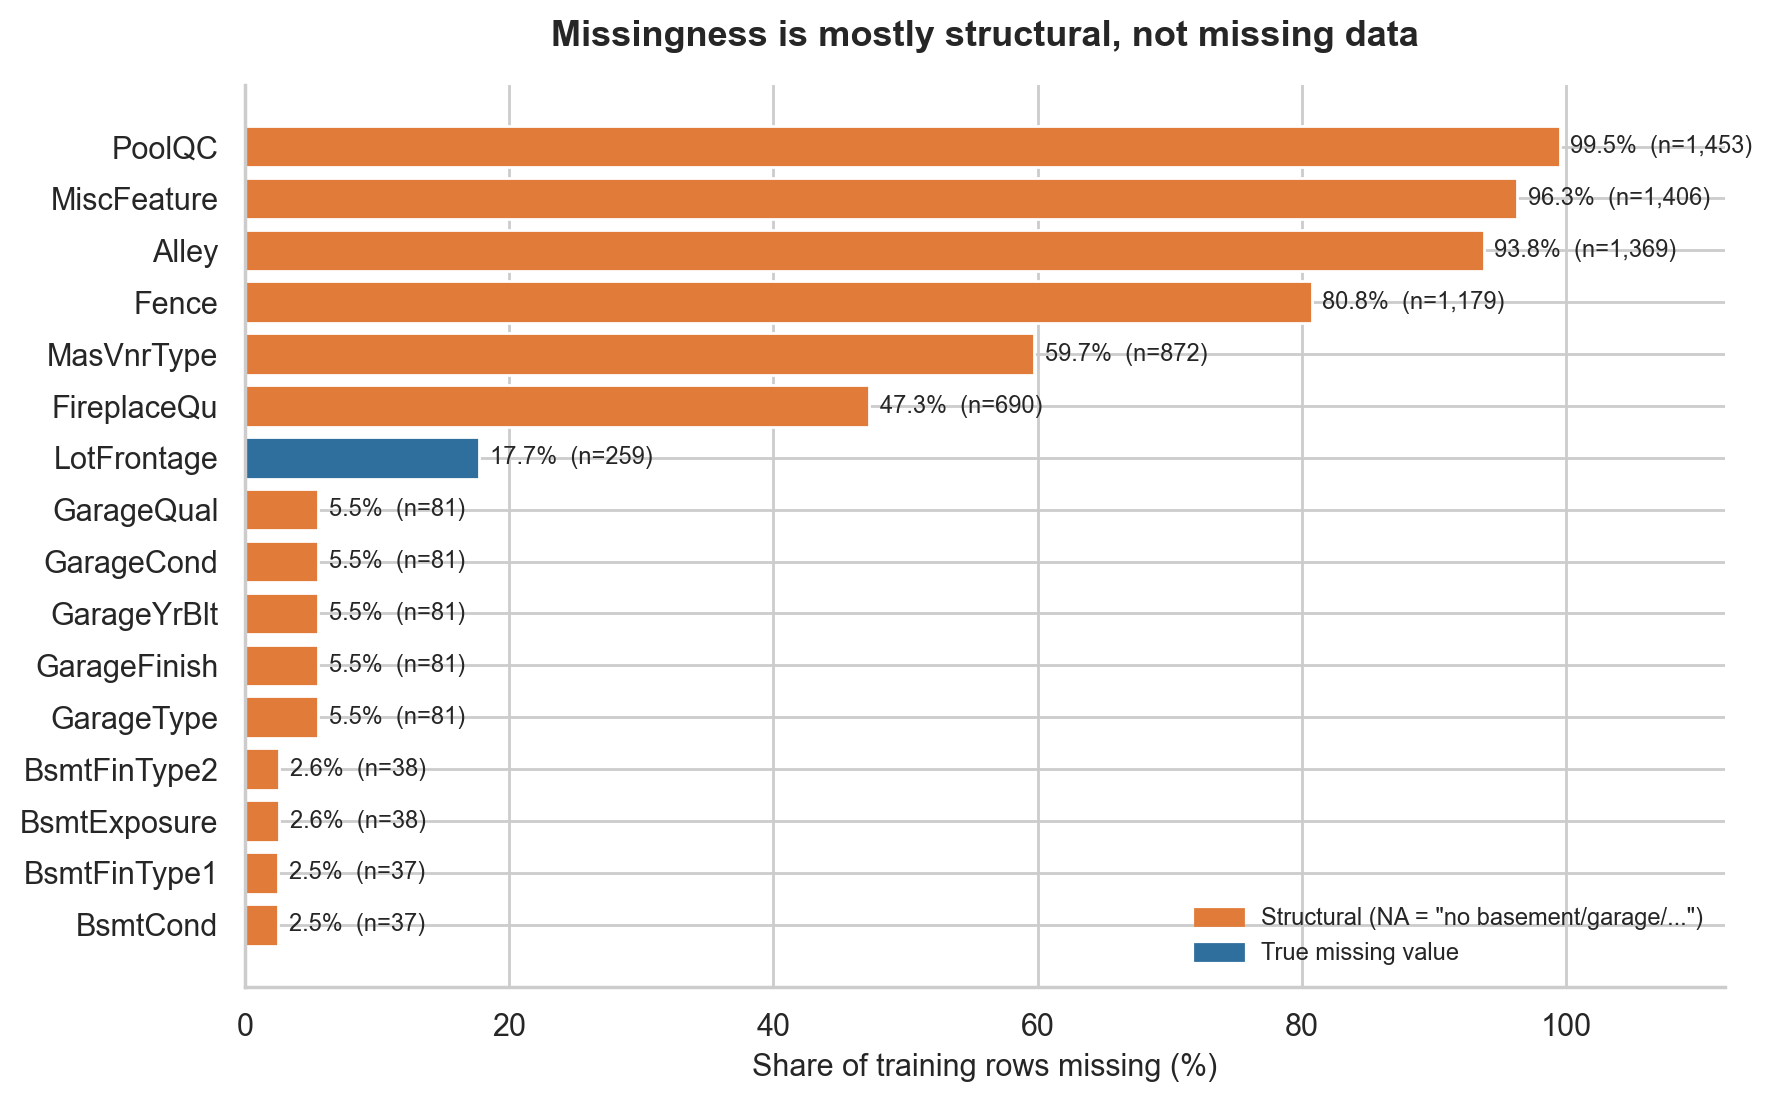

In [5]:
from IPython.display import Image, display as show
show(Image(filename="figures/fig02_missing_values.png", width=780))

## 3. Cleaning

Three rules, applied to both splits in the same order:

1. **Structural `NA` → explicit `"None"` category** (and `0` for the matching
   area/count columns). This keeps the information *"no garage"* instead of
   destroying it.
2. **True missing values → imputed**, with the imputation value learned on the
   training split only. `LotFrontage` uses the neighbourhood median, because
   missingness is not random: 52% of cul-de-sac lots lack a frontage figure,
   against 13% of inside lots.
3. **Impossible values → repaired**, not dropped.


In [6]:
clean_tr, clean_te, log = hp.clean(train, test)
print("remaining missing cells — train:", int(clean_tr.isna().sum().sum()),
      "| test:", int(clean_te.isna().sum().sum()))
print("\nmode-imputed columns:", json.dumps(log["mode_imputed"], indent=2))
print("garage years clipped:", log["garage_year_clipped"])
print("veneer types repaired:", log["veneer_type_repaired"])

remaining missing cells — train: 0 | test: 0

mode-imputed columns: {
  "Electrical": {
    "train": 1,
    "test": 0,
    "value": "SBrkr"
  },
  "MSZoning": {
    "train": 0,
    "test": 4,
    "value": "RL"
  },
  "KitchenQual": {
    "train": 0,
    "test": 1,
    "value": "TA"
  },
  "SaleType": {
    "train": 0,
    "test": 1,
    "value": "WD"
  },
  "Functional": {
    "train": 0,
    "test": 2,
    "value": "Typ"
  },
  "Exterior1st": {
    "train": 0,
    "test": 1,
    "value": "VinylSd"
  },
  "Exterior2nd": {
    "train": 0,
    "test": 1,
    "value": "VinylSd"
  },
  "Utilities": {
    "train": 0,
    "test": 2,
    "value": "AllPub"
  }
}
garage years clipped: 2
veneer types repaired: 8


**Outliers.** The classic anomaly in this dataset is a handful of very large
houses sold cheaply. Two sales have more than 4,000 sq ft above grade and a price
below $300k: they are partial sales, i.e. the house was not finished when the
sale was recorded (`SaleCondition = "Partial"`). They are real transactions, so
they are **flagged, not deleted**; only the modelling matrix excludes them. The
other two very large houses ($745k and $755k) are genuine luxury sales and stay.


        Id  GrLivArea  SalePrice SaleCondition  YearBuilt
523    524       4676     184750       Partial       2007
1298  1299       5642     160000       Partial       2008

flagged: 2 rows | ids: [524, 1299]


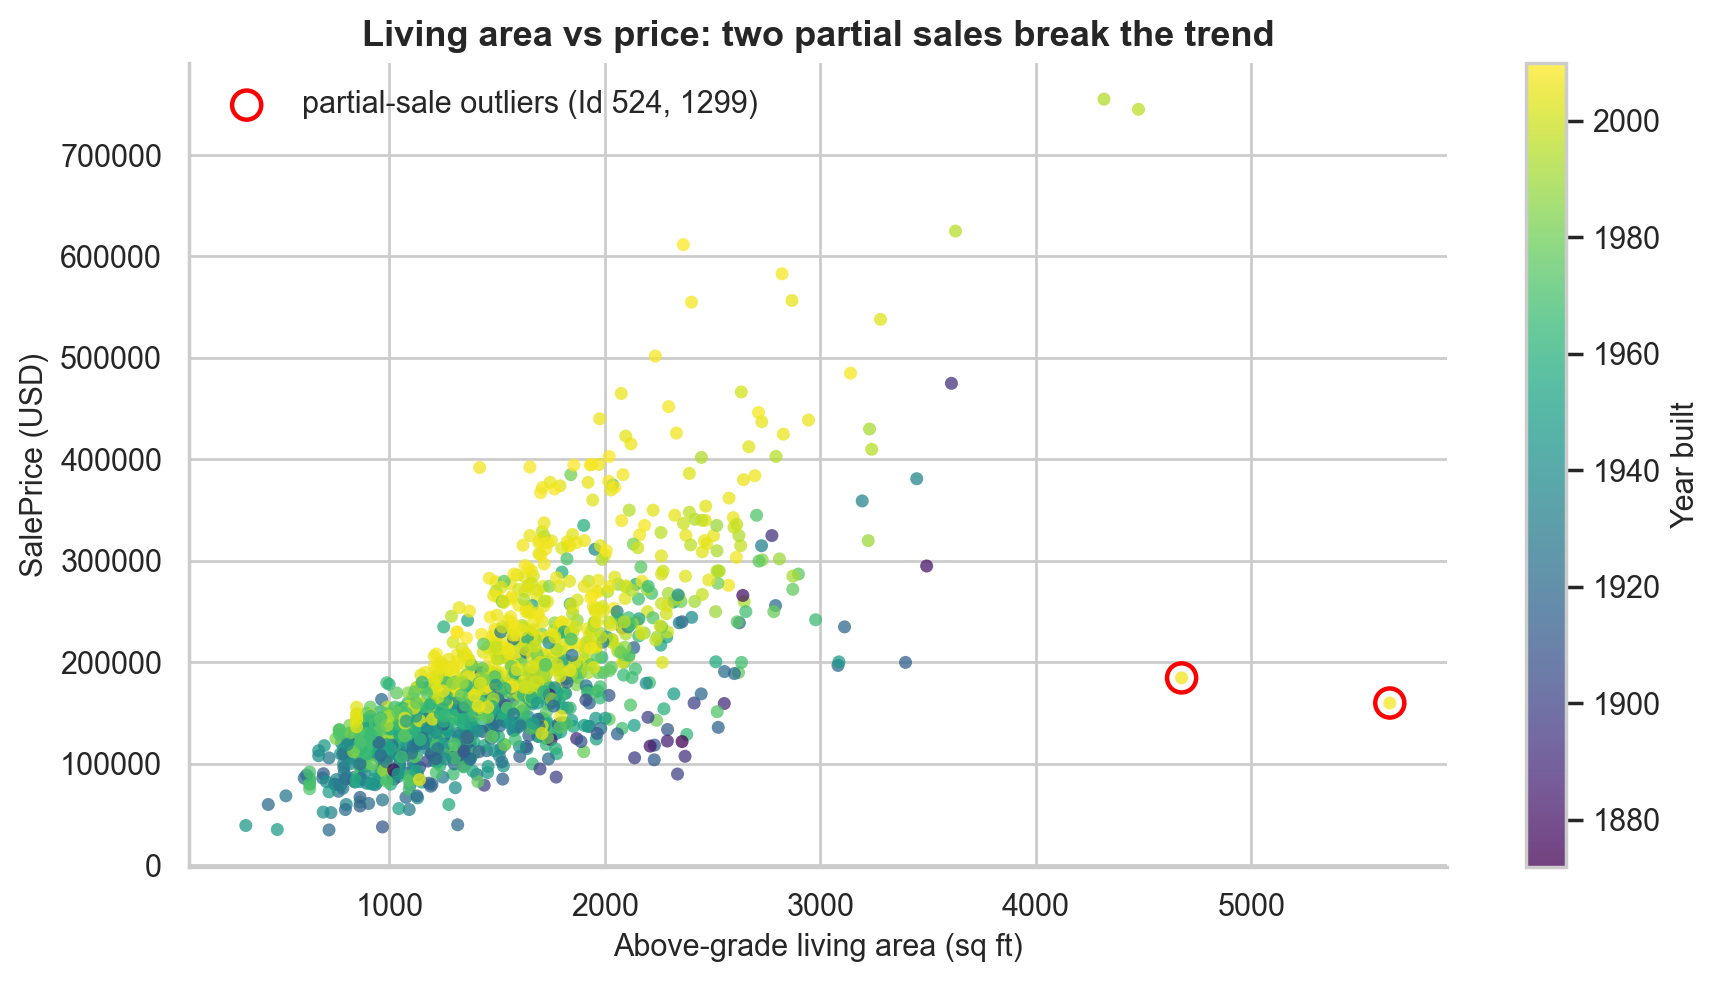

In [7]:
flag = (clean_tr.GrLivArea > 4000) & (clean_tr.SalePrice < 300000)
print(clean_tr.loc[flag, ["Id", "GrLivArea", "SalePrice", "SaleCondition", "YearBuilt"]])
print("\nflagged:", int(flag.sum()), "rows | ids:", clean_tr.loc[flag, "Id"].tolist())
show(Image(filename="figures/fig05_size_price.png", width=760))

### 3.1 Ordinal encoding

Quality and condition labels are ordered (`Po < Fa < TA < Gd < Ex`). Mapping them
to 1–5 preserves that order, which neither a label encoding by alphabet nor a
one-hot encoding does. `"None"` becomes 0 so that *"no basement"* stays at the
bottom of the scale rather than being treated as a missing value.


In [8]:
display(pd.DataFrame(
    [(k, str(v)) for k, v in hp.ORDINAL_MAPS.items()],
    columns=["column", "mapping"]).head(12))
print("ordinal columns encoded:", len(hp.ORDINAL_MAPS))

,column,mapping
0,LotShape,"{'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0}"
1,LandContour,"{'Lvl': 3, 'Bnk': 2, 'HLS': 1, 'Low': 0}"
2,LandSlope,"{'Gtl': 2, 'Mod': 1, 'Sev': 0}"
3,ExterQual,"{'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, ..."
4,ExterCond,"{'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, ..."
5,BsmtQual,"{'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, ..."
6,BsmtCond,"{'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, ..."
7,HeatingQC,"{'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, ..."
8,KitchenQual,"{'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, ..."
9,FireplaceQu,"{'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, ..."


ordinal columns encoded: 24


### 3.2 Rare levels

Levels with fewer than 10 training sales are folded into `"Other"`. Without this,
`RoofMatl` contributes eight columns of which six describe one or two houses, and
a model cannot estimate them. `Neighborhood` is deliberately excluded: it is the
strongest location signal, and the smoothed target encoding in Section 6 handles
its small levels instead of erasing them.


In [9]:
ord_tr, ord_te = hp.ordinal_encode(clean_tr, clean_te)
rare_tr, rare_te, rare_log = hp.collapse_rare(ord_tr, ord_te)
display(pd.DataFrame([
    {"column": k, "levels_before": v["n_levels_raw"], "levels_after": v["n_levels_kept"],
     "collapsed": ", ".join(v["collapsed"][:5]) + (" ..." if len(v["collapsed"]) > 5 else "")}
    for k, v in rare_log.items()]).head(10))

,column,levels_before,levels_after,collapsed
0,MSSubClass,15,14,40
1,LotConfig,5,4,FR3
2,Condition1,9,6,"PosA, RRNn, RRNe"
3,Condition2,8,1,"Feedr, Artery, RRNn, PosN, PosA ..."
4,HouseStyle,8,7,2.5Fin
5,RoofStyle,6,4,"Mansard, Shed"
6,RoofMatl,8,2,"WdShngl, WdShake, Metal, Membran, Roll ..."
7,Exterior1st,15,10,"BrkComm, Stone, AsphShn, ImStucc, CBlock"
8,Exterior2nd,16,11,"Brk Cmn, Stone, AsphShn, Other, CBlock"
9,Foundation,6,4,"Stone, Wood"


## 4. Exploratory analysis

### 4.1 The target

`SalePrice` ranges from $34,900 to $755,000 with a mean of $180,921 and a median
of $163,000: the mean sits above the median, which is the signature of a
right-skewed distribution (skew 1.88). `log(SalePrice)` brings the skew to 0.12. The
practical consequence is that models should be fitted on the log target and
scored after back-transformation, or evaluated with a metric that does not
punish the expensive tail disproportionately.


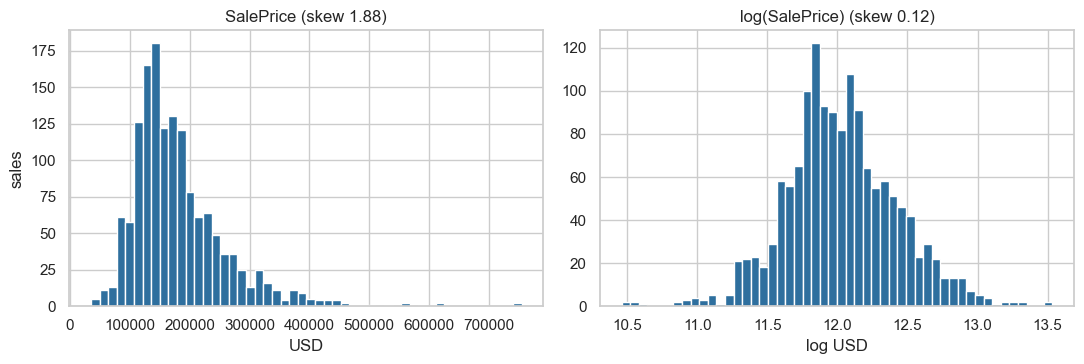

,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.0,79443.0,34900.0,129975.0,163000.0,214000.0,755000.0


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(train.SalePrice, bins=50, color="#2E6F9E")
ax[0].set(title="SalePrice (skew %.2f)" % train.SalePrice.skew(), xlabel="USD", ylabel="sales")
ax[1].hist(np.log(train.SalePrice), bins=50, color="#2E6F9E")
ax[1].set(title="log(SalePrice) (skew %.2f)" % np.log(train.SalePrice).skew(), xlabel="log USD")
plt.tight_layout(); plt.show()

display(train.SalePrice.describe().round(0).to_frame().T)

### 4.2 Which variables move with price?

`OverallQual` (r = 0.79) and `GrLivArea` (r = 0.71) are far ahead of everything
else; `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`, `FullBath` and
`YearBuilt` form a second tier around 0.5–0.65. Because the predictors are also
correlated with each other, the ranking is descriptive, not causal.


,correlation with SalePrice
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
YearRemodAdd,0.507


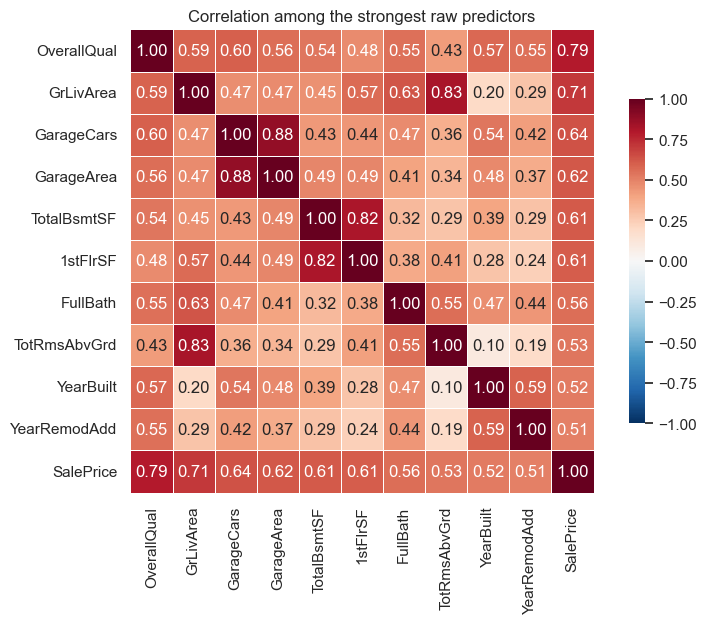

In [11]:
num = train.select_dtypes("number").drop(columns=["Id"])
corr = num.corr()["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)
display(corr.head(12).round(3).to_frame("correlation with SalePrice"))

top = corr.head(10).index.tolist()
fig, ax = plt.subplots(figsize=(8.4, 6.4))
sns.heatmap(train[top + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlation among the strongest raw predictors")
plt.tight_layout(); plt.show()

### 4.3 Quality, size and location

Quality behaves almost like a price ladder: the median rises from $50k at
`OverallQual = 1` to $432k at 10, and the interquartile boxes barely overlap
between adjacent grades. Size works the same way but with more dispersion, and
location shifts the whole distribution: the median price in Northridge Heights
($315k) is 3.6 times that in Meadow Village ($88k).


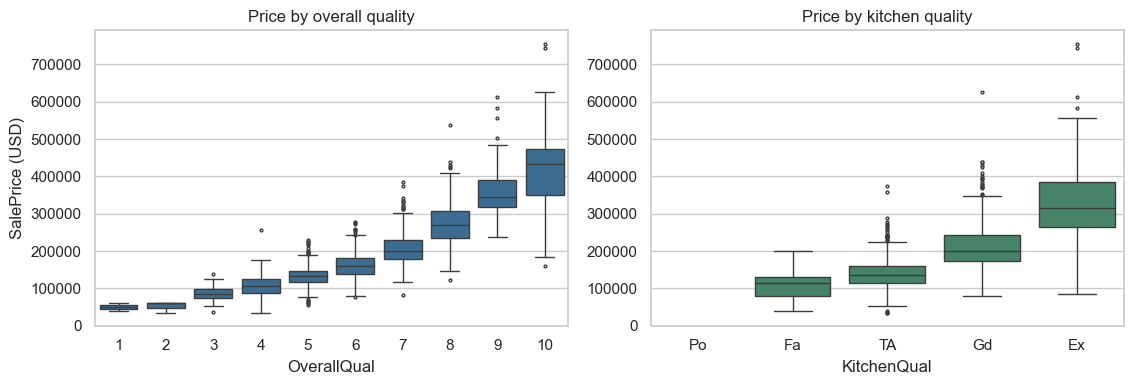

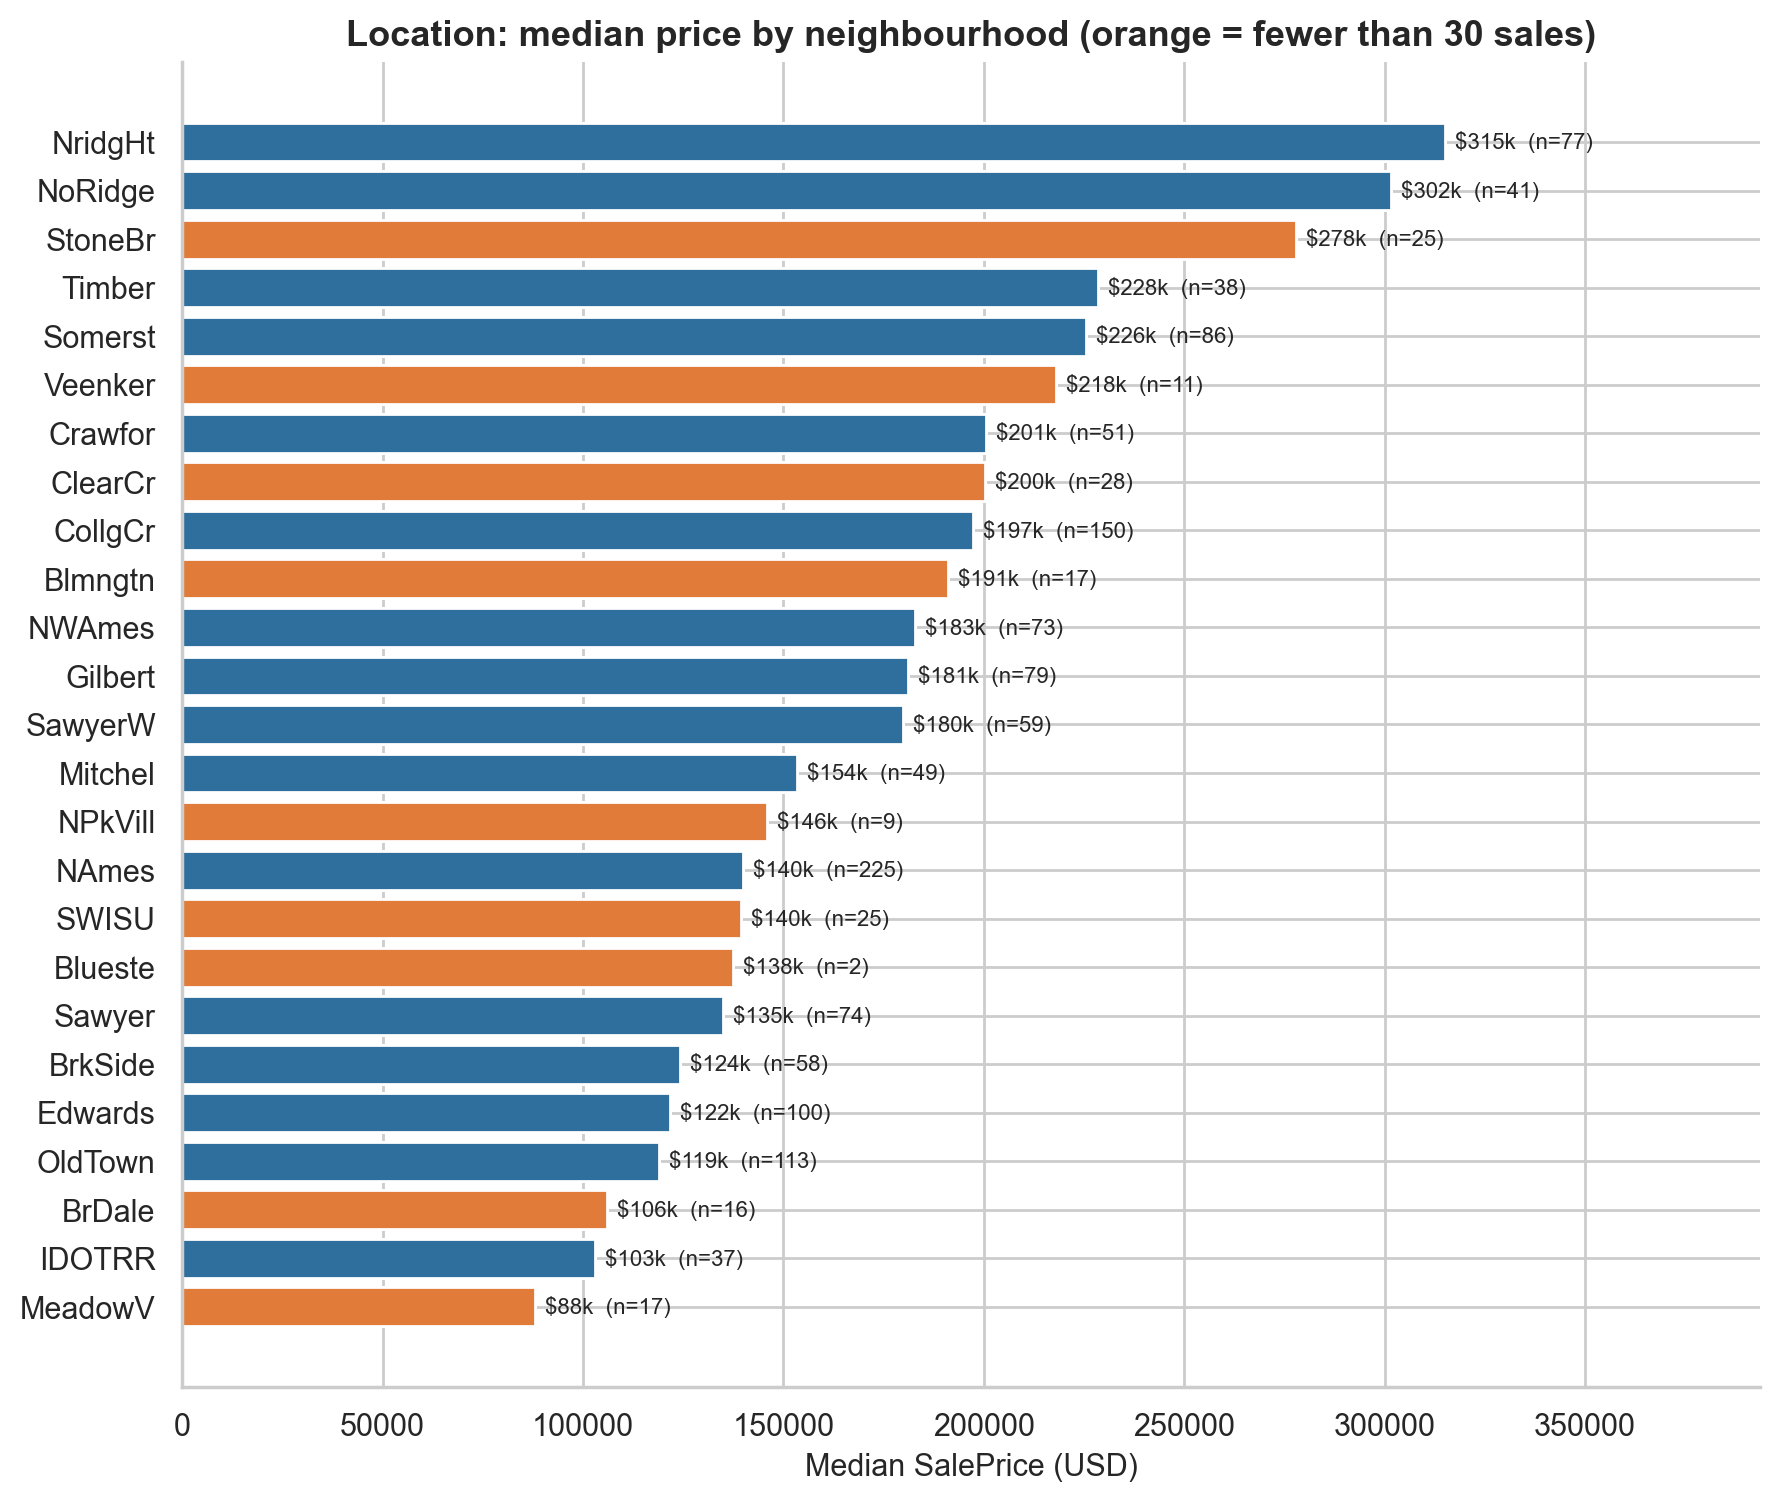

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
sns.boxplot(data=train, x="OverallQual", y="SalePrice", color="#2E6F9E", fliersize=2, ax=ax[0])
ax[0].set(title="Price by overall quality", ylabel="SalePrice (USD)", xlabel="OverallQual")
sns.boxplot(data=train, x="KitchenQual", y="SalePrice", order=["Po","Fa","TA","Gd","Ex"],
            color="#3C8D6B", fliersize=2, ax=ax[1])
ax[1].set(title="Price by kitchen quality", ylabel="", xlabel="KitchenQual")
plt.tight_layout(); plt.show()

show(Image(filename="figures/fig06_neighborhood.png", width=700))

### 4.4 Time and sale circumstances

Sales cluster in May–July, and the 2010 median is visibly lower than 2006–2009 —
a small but real market effect worth encoding as `HouseAge = YrSold - YearBuilt`.
`SaleCondition` also matters: partial (newly built) sales sit low relative to
their size, and `Abnorml` sales sit low relative to their quality, which is why
the two flagged outliers belong to the partial group.


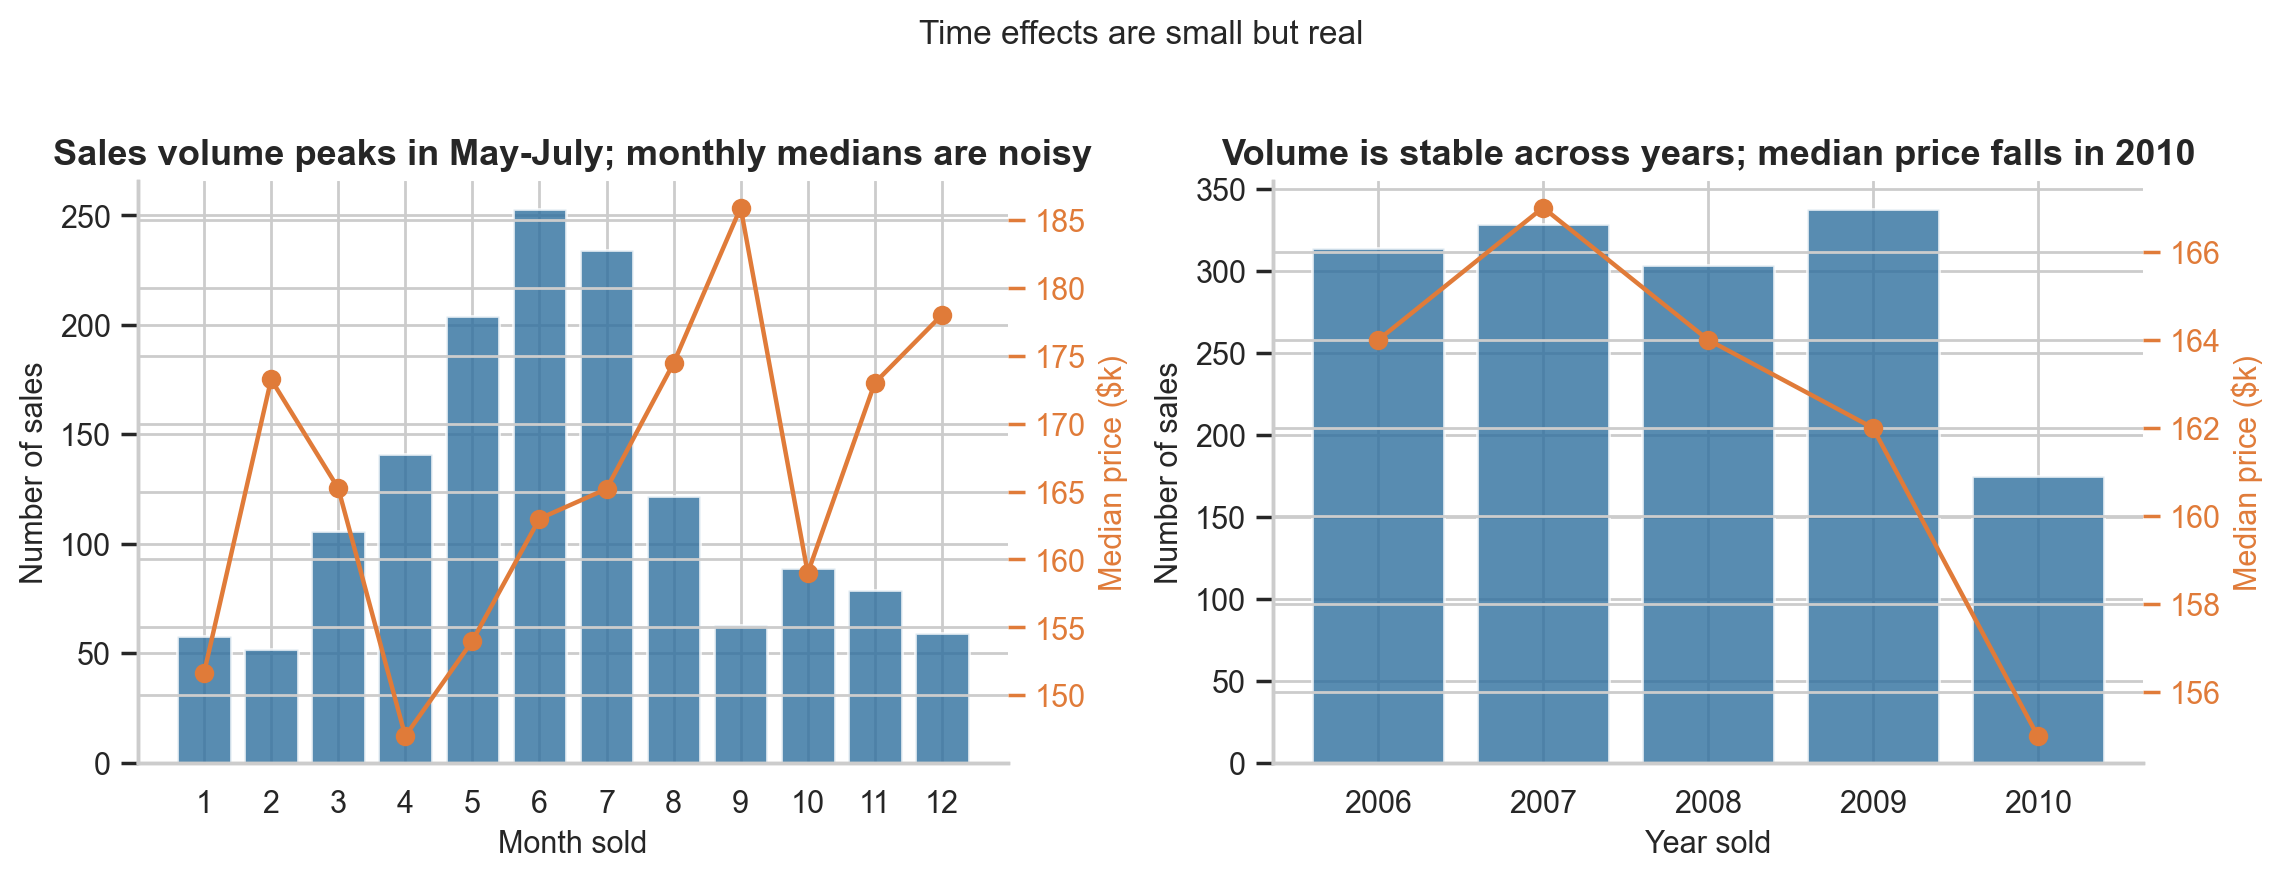

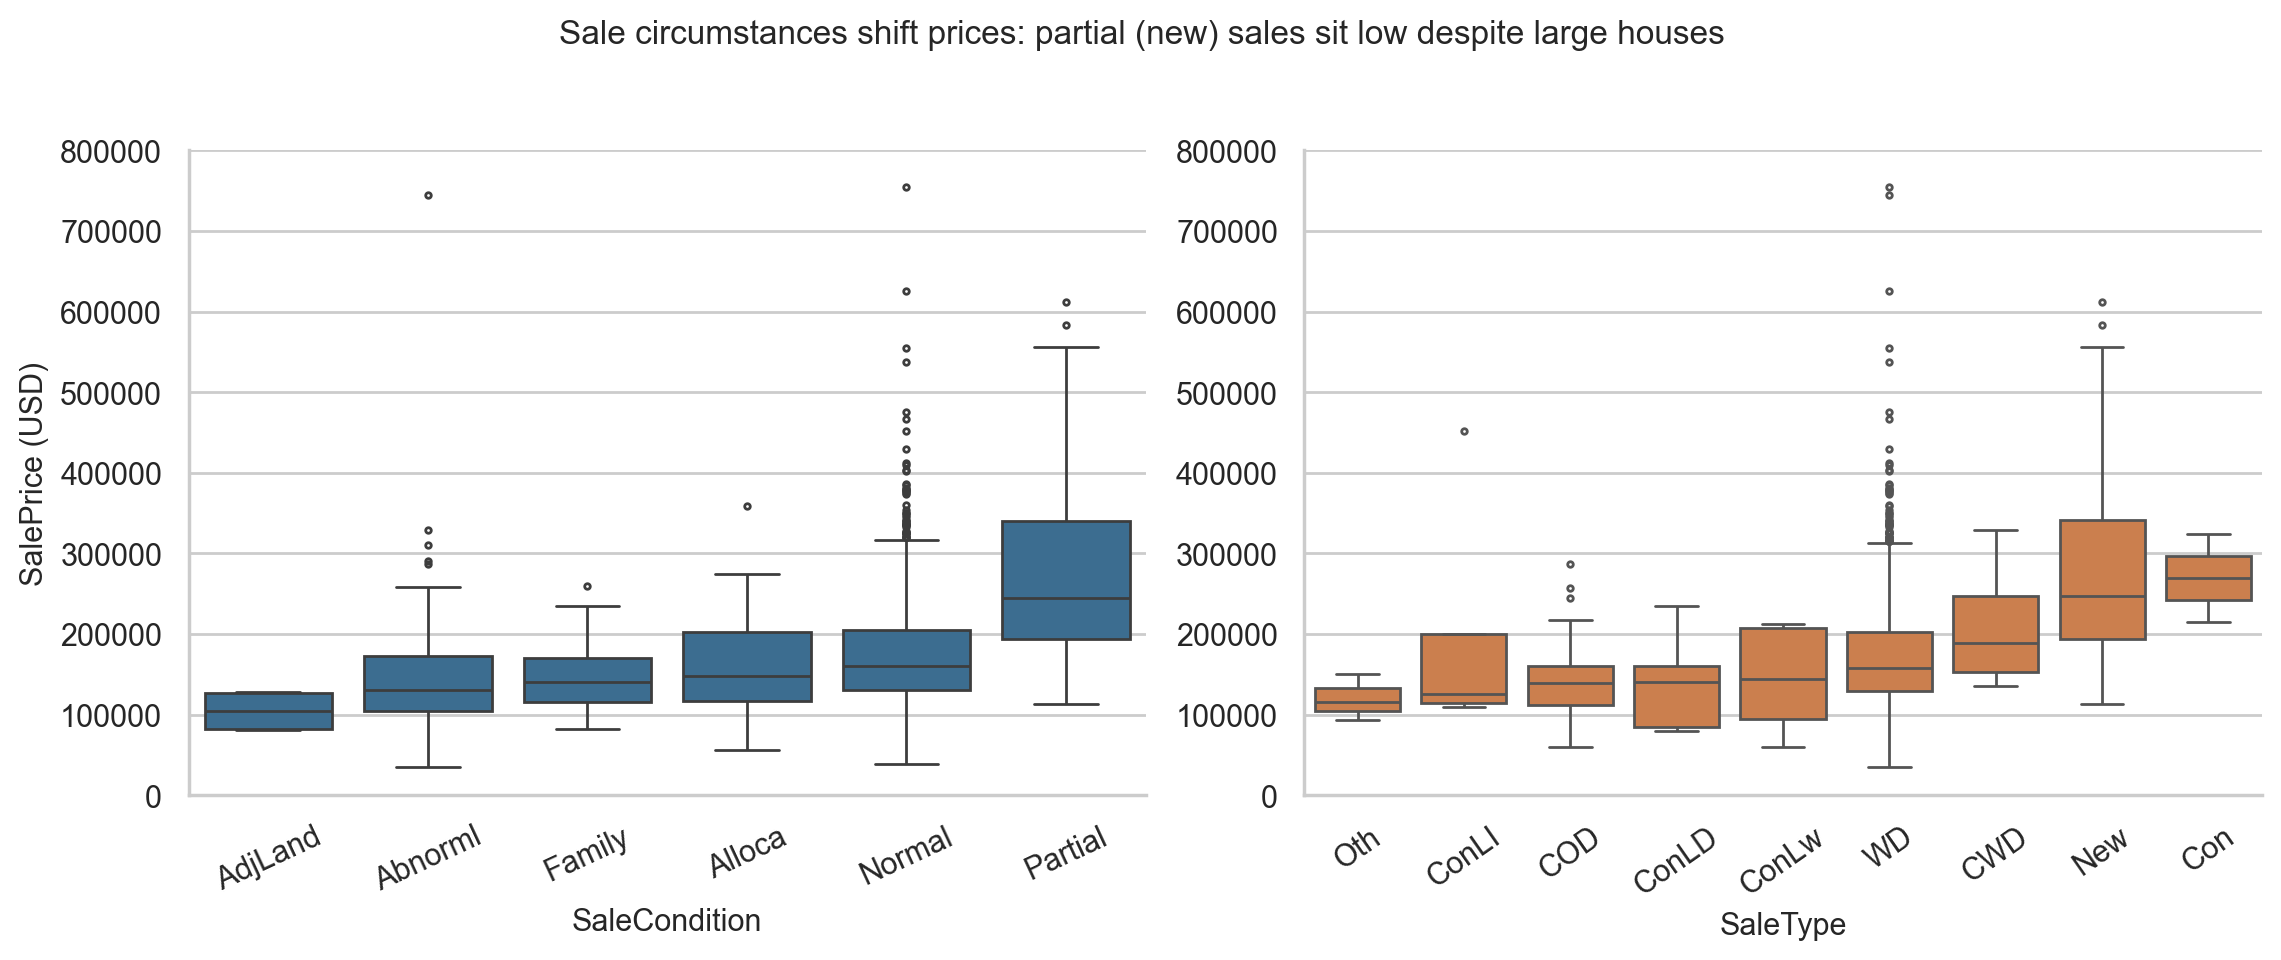

In [13]:
show(Image(filename="figures/fig10_seasonality.png", width=860))
show(Image(filename="figures/fig08_sale_circumstances.png", width=860))

### 4.5 Redundancy

Two pairs are almost duplicates: `TotalBsmtSF` vs `1stFlrSF` (r = 0.82) and
`GarageCars` vs `GarageArea` (r = 0.88). For linear models this inflates
standard errors; for trees it merely splits importance between twins. The
engineered `TotalSF` and `GarageAreaPerCar` replace the duplicated pairs with one
interpretable quantity each.


  TotalBsmtSF vs 1stFlrSF      r = 0.820
   GarageCars vs GarageArea    r = 0.882
    GrLivArea vs TotRmsAbvGrd  r = 0.825


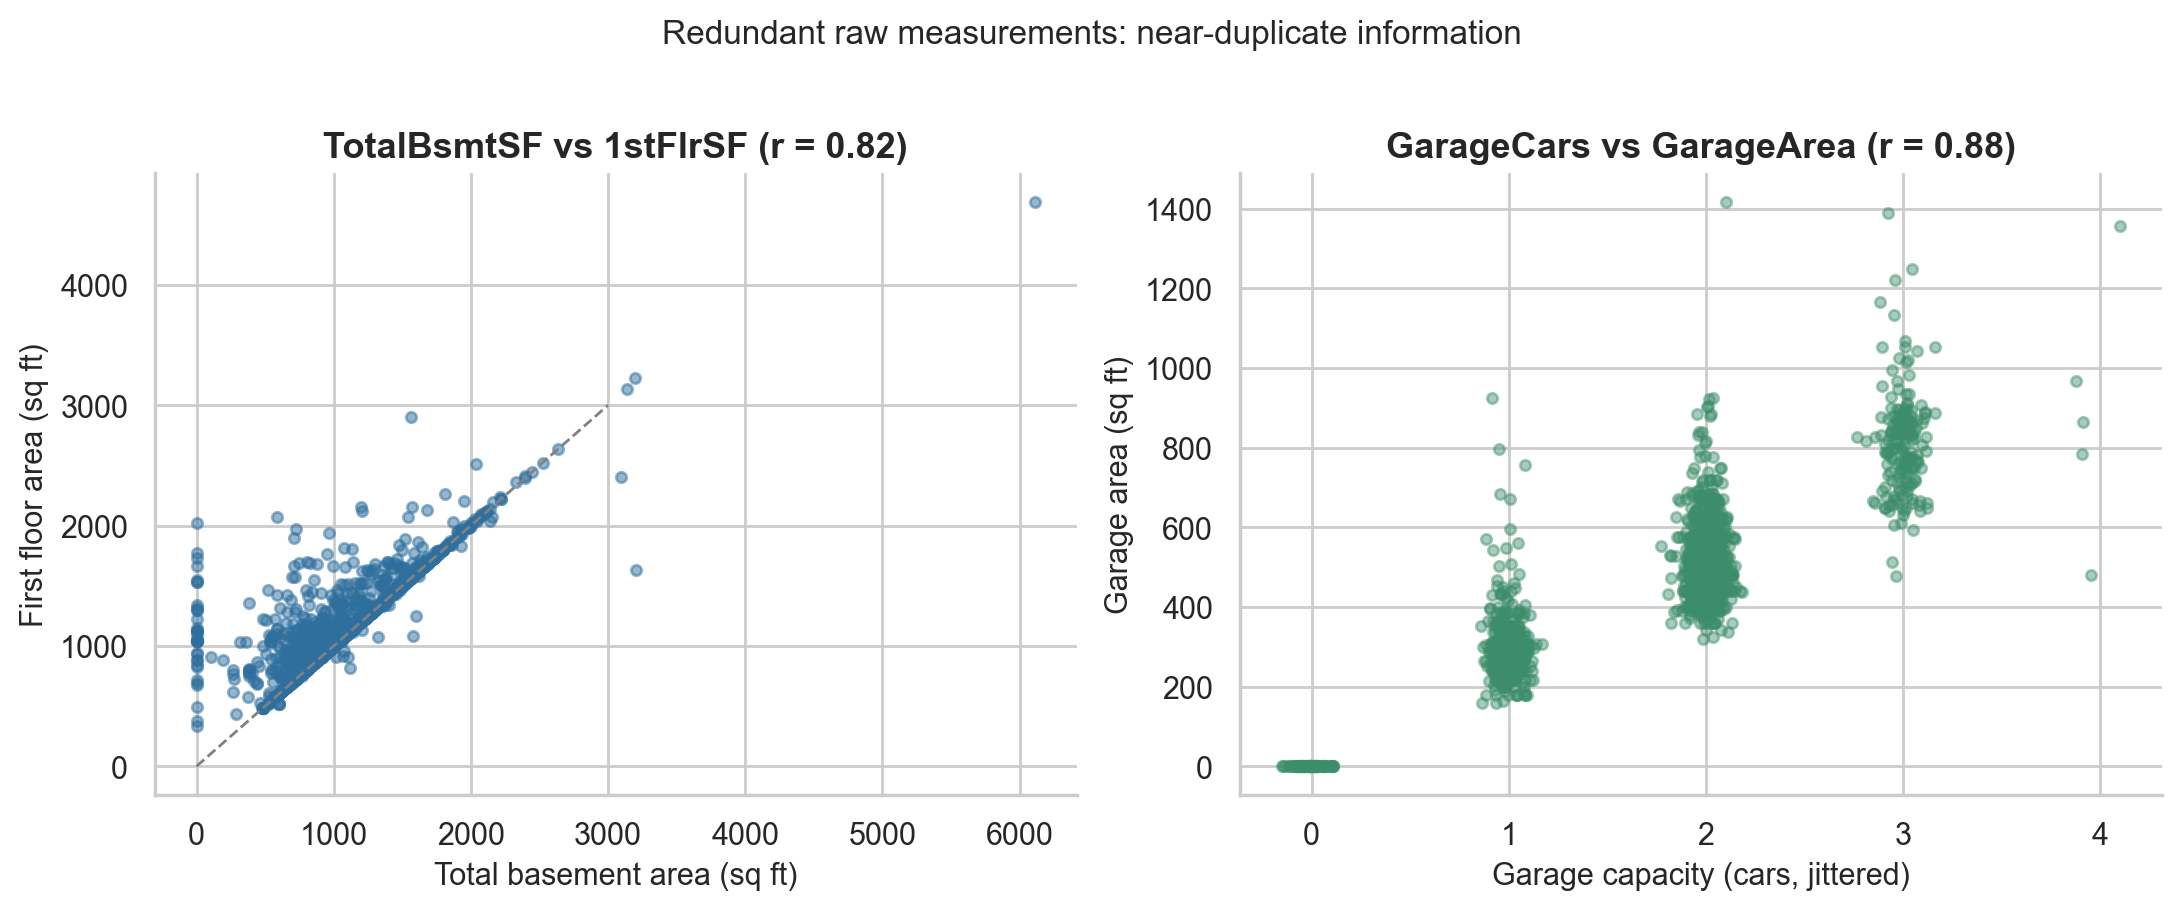

In [14]:
for a, b in [("TotalBsmtSF", "1stFlrSF"), ("GarageCars", "GarageArea"),
             ("GrLivArea", "TotRmsAbvGrd")]:
    print(f"{a:>13} vs {b:<13} r = {train[a].corr(train[b]):.3f}")
show(Image(filename="figures/fig11_multicollinearity.png", width=860))

## 5. Feature engineering

Thirty-six features in six families. The rules are: every feature must be
computable on a single row without the target, must have a meaning a reader can
state in one sentence, and must not duplicate an existing column.

| Family | Examples | Why |
|---|---|---|
| Size | `TotalSF`, `TotalFinSF`, `TotalBath`, `TotalPorchSF`, `AvgRoomSF` | the value of a house is driven by usable space, not by which floor it is on |
| Quality | `QualScore`, `OverallGrade`, `QualxSF`, `CondScore` | quality and size interact: a large poor house is not a large good house |
| Age | `HouseAge`, `RemodAge`, `GarageAge`, `IsNew`, `IsRemodeled` | absolute year is meaningless across a 2006–2010 test window |
| Presence | `HasBsmt`, `HasGarage`, `HasFireplace`, `HasPool`, … | separates *"absent"* from *"small"* |
| Ratios | `BsmtFinRatio`, `LivAreaRatio`, `BedroomRatio` | composition matters more than raw counts |
| Time | `MoSoldSin`, `MoSoldCos` | keeps month cyclical instead of ordinal 1–12 |

Heavy-tailed areas are additionally logged (`log_LotArea`, `log_GrLivArea`,
`log_TotalSF`, `log_LotFrontage`) for the linear models; trees are insensitive to
the transform but it costs nothing.


In [15]:
feat = hp.engineer(rare_tr.copy())
new_cols = [c for c in feat.columns if c not in rare_tr.columns]
print(f"{len(new_cols)} engineered columns")
display(pd.DataFrame({
    "feature": new_cols,
    "train_mean": [round(feat[c].mean(), 2) for c in new_cols],
    "train_max": [round(feat[c].max(), 1) for c in new_cols],
}).head(20))

36 engineered columns


,feature,train_mean,train_max
0,TotalSF,2567.05,11752.0
1,TotalFinSF,2005.65,11286.0
2,TotalBath,2.21,6.0
3,TotalPorchSF,181.33,1027.0
4,AvgRoomSF,230.91,470.2
5,BsmtFinSF,490.19,5644.0
6,OverallGrade,33.86,90.0
7,QualScore,19.18,28.0
8,QualxSF,9673.96,56420.0
9,QualxTotalSF,16416.03,117520.0


### 5.1 Location encoding

`Neighborhood` is categorical with 25 levels, several with fewer than 10 sales.
A one-hot encoding of a 6-sale neighbourhood is noise. The alternative used here
is **out-of-fold smoothed target encoding**: each training row receives the mean
log price of the *other* four folds, shrunk towards the global mean with
`m = 10` pseudo-observations, and the test rows receive the full-train mapping.
The out-of-fold step is what keeps it honest — a row never sees its own price.


In [16]:
te_col, te_test = hp.target_encode(rare_tr, rare_te)
print("train encoding — unique values:", te_col.nunique(), "| range:",
      round(te_col.min(), 3), "-", round(te_col.max(), 3))
print("corr(encoding, log price) =", round(np.corrcoef(te_col, np.log(rare_tr.SalePrice))[0, 1], 3))
print("\ncheck: same neighbourhood, different folds -> different values")
print(pd.DataFrame({"Neighborhood": rare_tr.Neighborhood.values, "encoding": te_col.values})
      .query("Neighborhood == 'NoRidge'").head(5))

train encoding — unique values: 120 | range: 11.562 - 12.547
corr(encoding, log price) = 0.737

check: same neighbourhood, different folds -> different values
    Neighborhood   encoding
4        NoRidge  12.546024
85       NoRidge  12.530889
226      NoRidge  12.530889
231      NoRidge  12.499053
272      NoRidge  12.546024


## 6. Final matrix

Nominal variables are one-hot encoded against a shared column space (the test
rows are reindexed to the training columns, so a level that appears only in test
becomes all-zero rather than a new column). The two flagged partial sales are
removed from the modelling matrix; `train_clean.csv` still contains them.


In [17]:
out = hp.build()
X, Xt = out["train"], out["test"]
print(f"modelling matrix: train {X.shape}, test {Xt.shape}")
print("missing values:", int(X.isna().sum().sum()), "| infinities:",
      int(np.isinf(X.drop(columns=['Id','SalePrice'])).sum().sum()))
print("target present:", "SalePrice" in X.columns, "| ids aligned:", int(X.Id.max()), int(Xt.Id.min()))
print("\nengineered + one-hot columns:", X.shape[1] - 2)
assert X.drop(columns=["Id", "SalePrice"]).isna().sum().sum() == 0
assert list(X.columns.drop("SalePrice")) == list(Xt.columns)
print("sanity checks passed")

modelling matrix: train (1458, 252), test (1459, 251)
missing values: 0 | infinities: 0
target present: True | ids aligned: 1460 1461

engineered + one-hot columns: 250
sanity checks passed


### 6.1 What the matrix contains

| Block | Columns |
|---|---|
| raw numeric + ordinal (0–5 scales) | 58 |
| hand-built engineered features | 36 |
| out-of-fold neighbourhood encoding | 1 |
| one-hot nominal levels | 155 |
| identifiers | `Id`, `SalePrice` |

The engineered features carry the signal of the raw quantities they summarise:
`QualxTotalSF` correlates 0.86 with price, against 0.78 for the raw `TotalSF`.


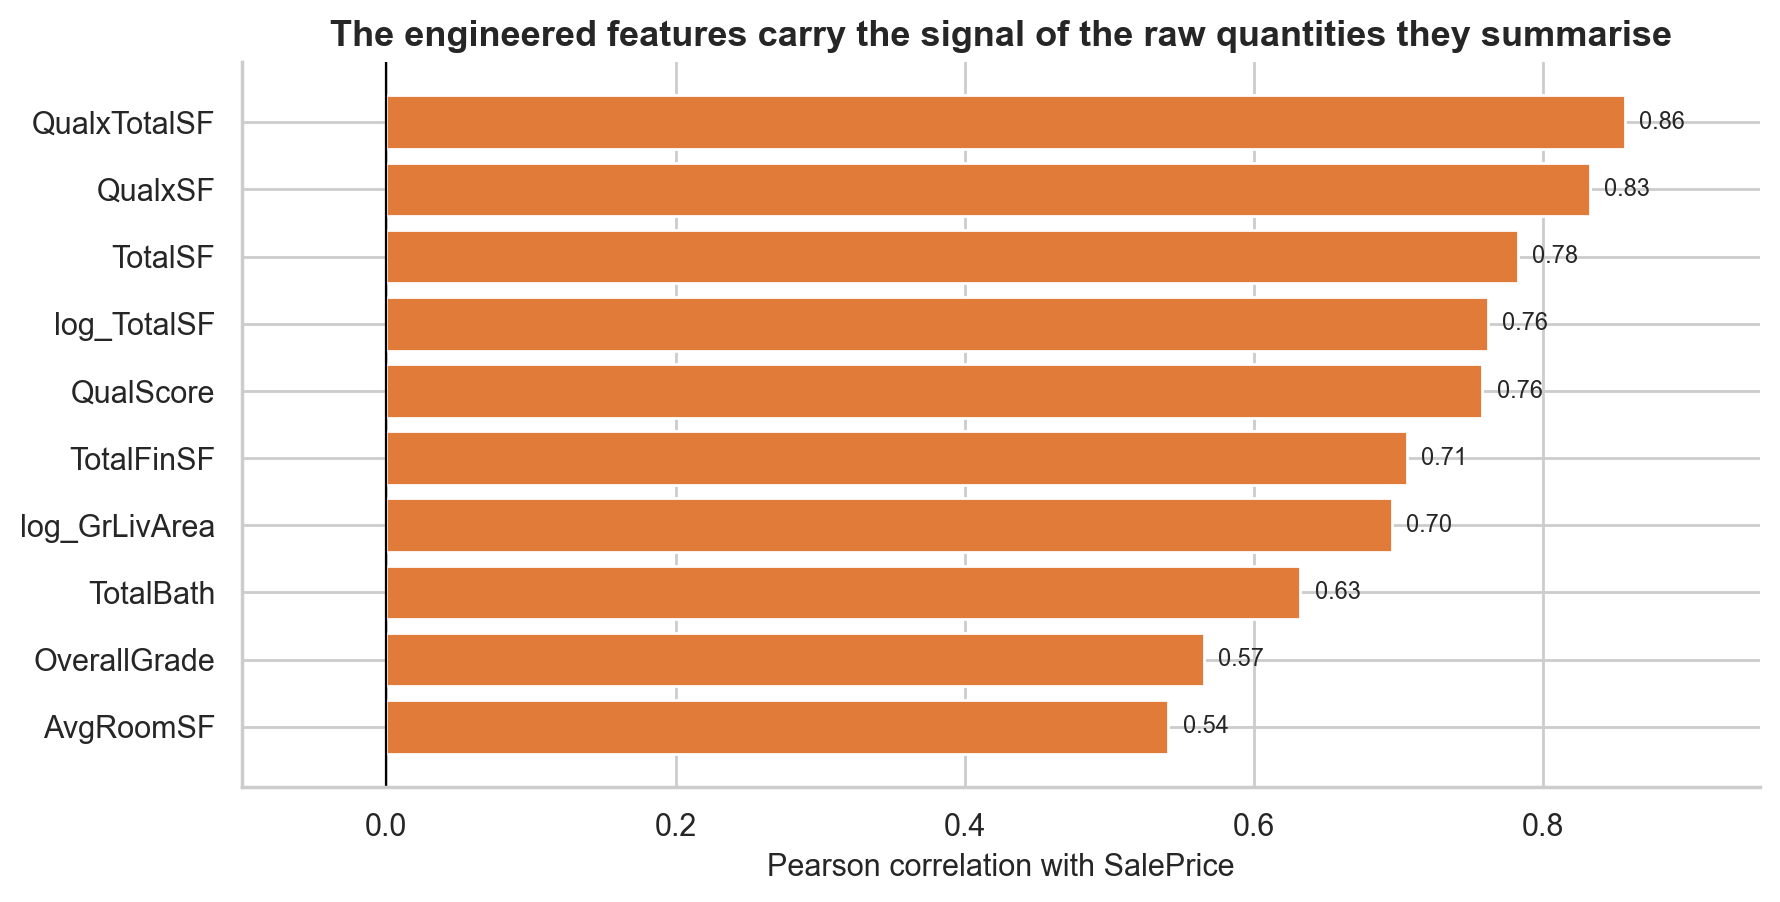

columns with zero variance in train: 0


,column,missing_train,pct_train,missing_test,interpretation
28,BsmtFinSF2,0,0.0,1,Structural: no basement
29,BsmtFinSF1,0,0.0,1,Structural: no basement
30,Exterior2nd,0,0.0,1,True missing
31,Exterior1st,0,0.0,1,True missing
32,Utilities,0,0.0,2,True missing
33,SaleType,0,0.0,1,True missing


In [18]:
show(Image(filename="figures/fig12_engineered_corr.png", width=780))
print("columns with zero variance in train:",
      (X.drop(columns=["Id", "SalePrice"]).std() == 0).sum())
display(pd.read_csv("reports/missing_values.csv").tail(6))

## 7. What the modelling section receives

- `data/train_features.csv` — 1,458 × 252, no missing values, `Id` and `SalePrice` included.
- `data/test_features.csv` — 1,459 × 251, same columns minus the target.
- `data/train_clean.csv` / `data/test_clean.csv` — cleaned but unencoded, for anyone
  who wants a different encoding.
- Caveats to carry into modelling:
  1. `NeighborhoodPriceTE` is out-of-fold **for the current training rows**. If the
     validation split changes, recompute it; otherwise the encoding leaks.
  2. The two partial-sale outliers are excluded from the matrix but not from
     `train_clean.csv`.
  3. `SalePrice` is right-skewed (1.88): fit on `log(SalePrice)`.
  4. Test `MSZoning`, `Utilities` and a few other fields needed imputation; the
     values used are recorded in `reports/audit.json`.


In [19]:
with open("reports/audit.json") as fh:
    info = json.load(fh)
print(json.dumps({
    "rows_modelled": info["rows_modelled"],
    "n_features_engineered": info["n_features_engineered"],
    "outliers_flagged": info["outliers_flagged"],
    "matrix": info["matrix"],
}, indent=2))

{
  "rows_modelled": 1458,
  "n_features_engineered": 252,
  "outliers_flagged": 2,
  "matrix": {
    "train": [
      1458,
      252
    ],
    "test": [
      1459,
      251
    ]
  }
}
